# Held-out evaluation
Every model is run through the matches in date order, predicting each match before it learns the result. The gap-to-outcome mapping and the ensemble weights are fit on the training seasons (first season skipped as burn-in); scores are on the last season (a partial season, the held-out test). Lower log loss / RPS is better. `baseline_home_rate` always predicts the overall home/draw/away rates.

In [1]:
%matplotlib inline
import sys, json, pathlib, warnings
warnings.filterwarnings("ignore")
# make the repo root importable no matter which folder the notebook is opened from
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "ratings").is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from ratings import base
from ratings.data import load_matches
from ratings.tune import PARAMS_PATH, load_best
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
from ratings.evaluate import evaluate, default_models

In [2]:
matches = {g: load_matches(g) for g in ("male", "female")}
results = {}
for g in ("male", "female"):
    results[g] = evaluate(matches[g], default_models(g), return_preds=True)   # table, predictions, mappers, test years
    print(f"== {g}  (test seasons {results[g][3]}, {results[g][0]['n'].iloc[0]} matches) ==")
    display(results[g][0].round(4))

== male  (test seasons [np.int32(2026)], 1579 matches) ==


,n,log_loss,rps,brier,accuracy,gd_mae,gd_rmse,xgd_mae
model,,,,,,,,
ensemble_ols,1579,0.9375,0.1902,0.5536,0.5643,1.3663,1.8325,0.9965
dixon_coles_xg,1579,0.9420,0.1915,0.5565,0.5687,1.3774,1.8422,1.0016
elo_xg,1579,0.9460,0.1926,0.5590,0.5668,1.3962,1.8947,1.0287
ridge_gd_xg,1579,0.9465,0.1933,0.5597,0.5522,1.3857,1.8609,1.0171
dixon_coles,1579,0.9547,0.1954,0.5650,0.5617,1.3967,1.8630,1.0262
ridge_gd,1579,0.9609,0.1975,0.5695,0.5529,1.4180,1.8937,1.0421
elo_wfe_autocorr,1579,0.9619,0.1977,0.5700,0.5478,1.4249,1.9149,1.0570
glicko,1579,0.9630,0.1983,0.5707,0.5560,1.4173,1.9090,1.0567
elo_sqrt,1579,0.9651,0.1987,0.5722,0.5472,1.4265,1.9121,1.0618


== female  (test seasons [np.int32(2026)], 2780 matches) ==


,n,log_loss,rps,brier,accuracy,gd_mae,gd_rmse,xgd_mae
model,,,,,,,,
ensemble_ols,2780,0.8879,0.1780,0.5204,0.6058,1.3887,1.9029,1.0228
dixon_coles_xg,2780,0.8893,0.1783,0.5210,0.6061,1.3956,1.9137,1.0382
elo_xg,2780,0.8939,0.1800,0.5244,0.5971,1.4232,1.9928,1.0673
ridge_gd,2780,0.8940,0.1802,0.5248,0.5917,1.4146,1.9486,1.0570
dixon_coles,2780,0.8952,0.1801,0.5249,0.5978,1.4129,1.9369,1.0625
glicko,2780,0.8982,0.1814,0.5270,0.5849,1.4390,2.0269,1.0909
elo_sqrt,2780,0.8999,0.1817,0.5282,0.5878,1.4460,2.0148,1.0971
pi,2780,0.9001,0.1820,0.5280,0.5917,1.4286,1.9820,1.0815
ridge_gd_xg,2780,0.9001,0.1822,0.5291,0.5896,1.4240,1.9570,1.0437


## Log loss by model

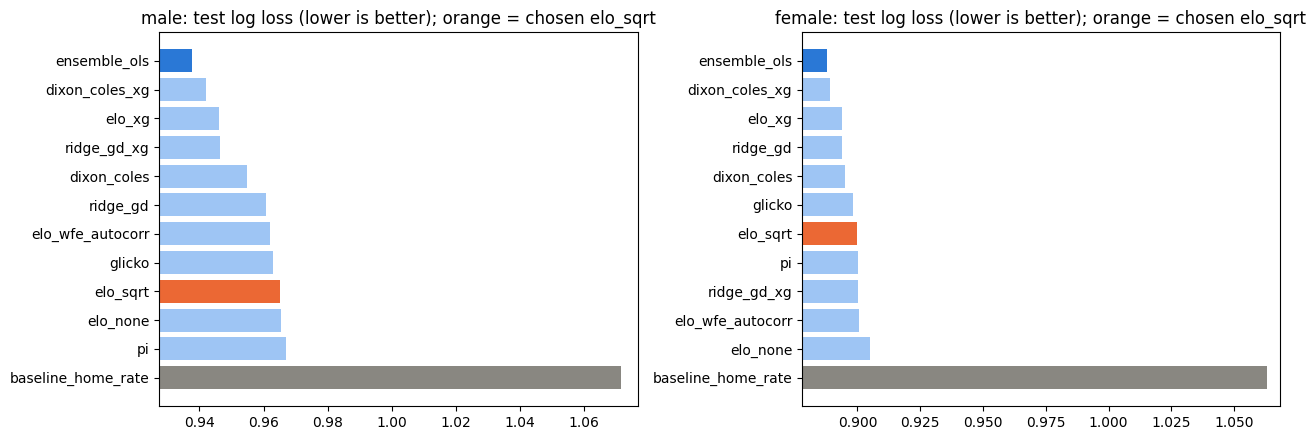

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, g in zip(axes, results):
    t = results[g][0]["log_loss"].sort_values(ascending=False)
    colors = ["#898781" if i == "baseline_home_rate" else "#eb6834" if i == "elo_sqrt" else "#2a78d6" if i == "ensemble_ols" else "#9ec5f4" for i in t.index]
    ax.barh(t.index, t.values, color=colors)
    ax.set_xlim(t.min() - 0.01, t.max() + 0.005)
    ax.set_title(f"{g}: test log loss (lower is better); orange = chosen elo_sqrt")
plt.tight_layout(); plt.show()

## Ensemble weights
The OLS ensemble stacks the standardised gaps of all models; weights fit on training seasons only. Highly correlated inputs make these unstable (some are negative).

In [4]:
display(pd.DataFrame({g: pd.Series(results[g][1]["ensemble_ols"].attrs["coef"]) for g in results}).round(3))

,male,female
elo_none,-0.394,-0.729
elo_sqrt,0.596,2.512
elo_wfe_autocorr,-0.317,-1.733
elo_xg,0.201,-0.172
pi,-0.004,0.123
glicko,0.193,0.300
dixon_coles,0.119,0.551
dixon_coles_xg,0.409,0.416
ridge_gd,-0.344,-0.577
ridge_gd_xg,0.465,0.657


## Calibration of the predicted home-win probability
Predictions are grouped into 10 equal-sized bins; a well-calibrated model lies on the diagonal.

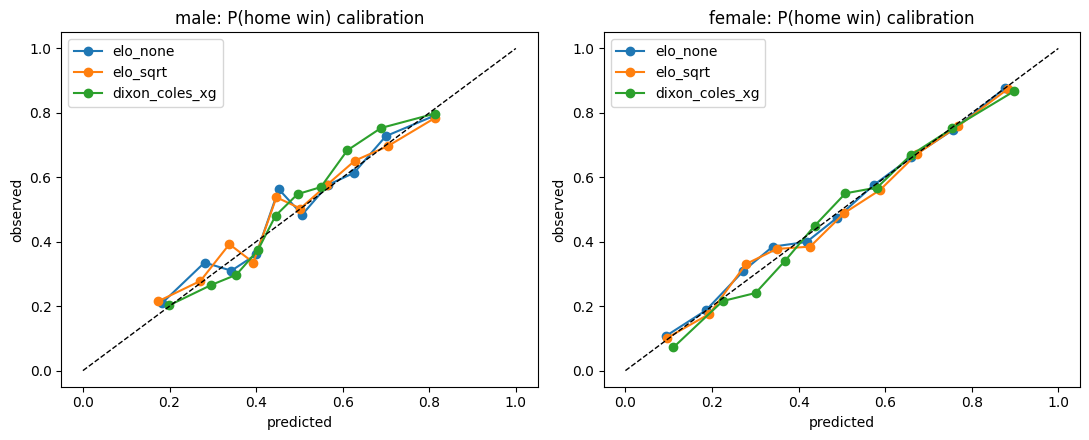

In [5]:
def calibration(ax, df, mapper, label, bins=10):
    p = base.outcome_probs(mapper, df["gap"].values)[:, 0]
    home_won = (df.hg > df.ag).values
    bin_of = pd.qcut(p, bins, duplicates="drop")
    by_bin = pd.DataFrame({"p": p, "y": home_won}).groupby(bin_of, observed=True).mean()
    ax.plot(by_bin.p, by_bin.y, "o-", label=label)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, g in zip(axes, results):
    table, preds, mappers, test_years = results[g]
    best_name = table.index[0] if table.index[0] != "ensemble_ols" else table.index[1]
    for name in ("elo_none", "elo_sqrt", best_name):
        df = preds[name]
        calibration(ax, df[df.year.isin(test_years)], mappers[name], name)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"{g}: P(home win) calibration"); ax.set_xlabel("predicted"); ax.set_ylabel("observed"); ax.legend()
plt.tight_layout(); plt.show()

## Does the rating gap track real goal difference?

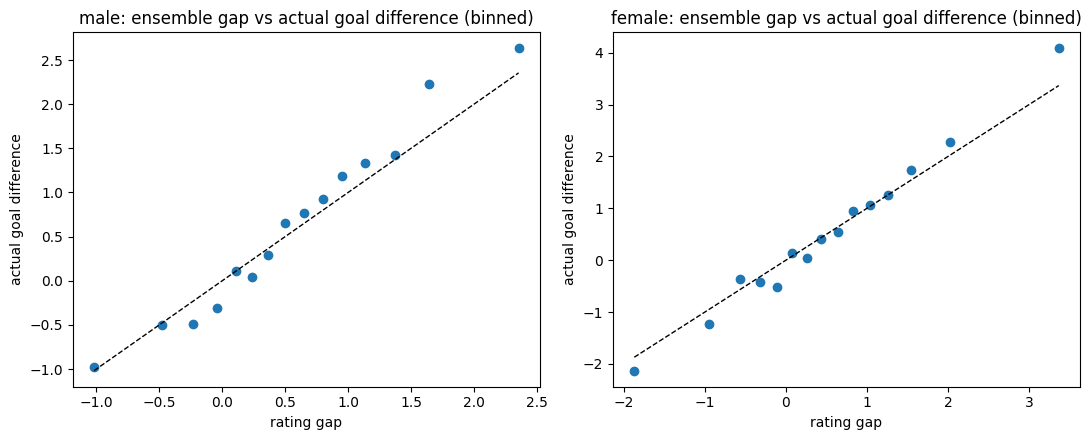

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, g in zip(axes, results):
    table, preds, mappers, test_years = results[g]
    df = preds["ensemble_ols"]
    df = df[df.year.isin(test_years)].copy()
    df["goal_diff"] = df.hg - df.ag
    df["bin"] = pd.qcut(df["gap"], 15, duplicates="drop")
    by_bin = df.groupby("bin", observed=True).agg(predicted=("gap", "mean"), actual=("goal_diff", "mean"))
    ax.scatter(by_bin.predicted, by_bin.actual)
    ax.plot(by_bin.predicted, by_bin.predicted, "k--", lw=1)
    ax.set_title(f"{g}: ensemble gap vs actual goal difference (binned)")
    ax.set_xlabel("rating gap"); ax.set_ylabel("actual goal difference")
plt.tight_layout(); plt.show()